# EduPredict AI: predicting student marks with a neural network built from scratch

**Problem.** Can an artificial neural network learn how a student's background, attendance, coursework and test scores
relate to the final marks, and how accurately can it estimate marks for students it has never seen?

**Approach.** A small network written in NumPy (no machine-learning library does the learning): one hidden layer of
16 ReLU neurons, a linear output neuron, mean-squared-error loss, backpropagation and gradient descent. The classic
neuron models from the syllabus (McCulloch-Pitts, Hebb's rule, the Delta rule) are shown as well.

**Everything happens in this notebook.** The dataset generator, preprocessing, the neural network (forward pass,
backpropagation, gradient descent), the evaluation metrics and the learning rules are all written in the cells below, and
nothing is imported from other project files. The only extra file is the dataset `data/edupredict_synthetic.csv`; if it is
missing, the notebook generates it. Only `numpy`, `pandas`, `matplotlib` and `scikit-learn` (for the train/test split only) are needed.

Run it with `pip install -r requirements.txt` and then *Run All* in Jupyter or VS Code (about a minute: it trains three networks).

> **The data is synthetic**: it is generated by the code in section 1, so it contains relationships chosen by the
> generator and no real student records. The accuracy below shows that the method works, not how real students behave.

**Contents:** 1 Dataset · 2 Explore · 3 Preprocessing and split · 4 The neural network · 5 Training ·
6 One prediction by hand · 7 Is backpropagation correct? · 8 Learning curves and weight changes · 9 Test results ·
10 One student, all subjects · 11 Classic neuron models · 12 Delta rule on the student data ·
13 Is 16 hidden neurons needed? · 14 Limitations and next steps

In [1]:
import copy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit   # used only to split students into train / validation / test

HERE = Path.cwd()
if (HERE / "notebooks" / "edupredict_walkthrough.ipynb").exists():     # notebook opened from the folder above
    HERE = HERE / "notebooks"
DATA_FILE = HERE / "data" / "edupredict_synthetic.csv"

pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE = "#0071e3", "#ff9f0a"
VARIANTS = ["early", "during_term", "late"]

## 1. Dataset
One row is one **student-subject** pair. There are 2,000 students and 8 subjects (Mathematics, Physics, Chemistry, Biology,
English, Computer Science, History, Economics); every student takes Mathematics, English and four others.

| Group | Columns |
|---|---|
| Identity | `student_id`, `subject` |
| Student | `gender`, `age`, `grade_level` (9-12) |
| Home | `parent_education` (0-4), `family_income_band` (1-5), `internet_access`, `commute_minutes` |
| Lifestyle | `part_time_job`, `extracurricular_hours`, `sleep_hours`, `stress_level` (1-5), `health_status` (1-5), `tutoring`, `past_failures` |
| Subject | `subject_interest` (1-5), `class_size` |
| Known at the start | `prev_year_score` (last year's mark in the subject, 0-100) |
| During the term | `study_hours_week`, `attendance_pct`, `assignment_completion_pct`, `late_submissions`, `assignment_avg_score`, `class_participation`, `quiz_avg_score` |
| Mid-term | `midterm_score` |
| **Target** | `final_marks` (0-100) = 0.6 x final exam + 0.2 x mid-term + 0.2 x assignments |
| Derived from the target (never used as inputs) | `final_exam_score`, `grade_letter`, `passed` |

**How it is generated.** Each student has a hidden *ability* and *motivation*; each student-subject pair adds a subject
talent, a teacher effect and a subject difficulty. Attendance, study hours, assignments, quiz, mid-term and exam scores
are then computed from these plus lifestyle factors, with random noise at every stage. The generator is deterministic
(fixed seed). You can skip reading it: the next cell is what matters.

In [2]:
# ---- dataset generator ----
SEED = 2026


N_STUDENTS = 2000


SUBJECTS_PER_STUDENT = 6


SUBJECTS = {"Mathematics": 1.0, "Physics": 1.2, "Chemistry": 1.0, "Biology": 0.6,
            "English": 0.2, "Computer Science": 0.8, "History": 0.3, "Economics": 0.7}


CORE = ["Mathematics", "English"]


def clip(x, lo, hi):
    return np.clip(x, lo, hi)


def make_students(rng, n):
    ability = rng.normal(0, 1, n)
    motivation = 0.3 * ability + rng.normal(0, 0.95, n)
    parent_edu = clip(np.round(2 + rng.normal(0, 1.1, n)), 0, 4)          # 0 none .. 4 postgraduate
    income = clip(np.round(0.6 * (parent_edu - 2) + 3 + rng.normal(0, 1, n)), 1, 5)
    grade_level = rng.choice([9, 10, 11, 12], n)
    return pd.DataFrame({
        "student_id": [f"S{i:04d}" for i in range(n)],
        "gender": rng.choice(["F", "M"], n),
        "grade_level": grade_level,
        "age": grade_level + 5 + rng.choice([0, 0, 0, 1], n),
        "parent_education": parent_edu.astype(int),
        "family_income_band": income.astype(int),
        "internet_access": (rng.random(n) < 0.55 + 0.08 * income).astype(int),
        "commute_minutes": clip(rng.gamma(2.2, 11, n), 3, 120).round().astype(int),
        "part_time_job": (rng.random(n) < clip(0.32 - 0.05 * income + 0.05 * (grade_level - 9), 0.02, 0.6)).astype(int),
        "extracurricular_hours": clip(rng.gamma(1.6, 1.6, n), 0, 14).round(1),
        "sleep_hours": clip(rng.normal(7.1, 1.0, n), 4, 10).round(1),
        "stress_level": clip(np.round(3 + 0.4 * (grade_level - 10) - 0.3 * motivation + rng.normal(0, 1, n)), 1, 5).astype(int),
        "health_status": clip(np.round(rng.normal(3.9, 0.9, n)), 1, 5).astype(int),
        "tutoring": (rng.random(n) < clip(0.05 + 0.06 * income, 0, 0.5)).astype(int),
        "past_failures": rng.choice([0, 1, 2, 3], n, p=[.78, .15, .05, .02]),
        "_ability": ability, "_motivation": motivation,
    })


def make_rows(rng, students):
    rows = []
    names = list(SUBJECTS)
    for _, s in students.iterrows():
        electives = rng.choice([x for x in names if x not in CORE], SUBJECTS_PER_STUDENT - len(CORE), replace=False)
        for subj in CORE + list(electives):
            aptitude = s._ability + rng.normal(0, 0.6)               # subject-specific talent
            interest = clip(np.round(3 + 0.5 * s._motivation + 0.4 * aptitude + rng.normal(0, 0.9)), 1, 5)
            teacher = rng.normal(0, 1)                               # teacher effectiveness (unobserved)
            class_size = int(clip(rng.normal(32, 6), 18, 48))
            study = clip(np.exp(0.9 + 0.35 * s._motivation + 0.12 * (interest - 3) - 0.25 * s.part_time_job
                                - 0.05 * s.extracurricular_hours + rng.normal(0, 0.45)), 0, 20)
            attendance = clip(92 + 4 * s._motivation - 0.08 * s.commute_minutes - 4 * s.part_time_job
                              + 1.5 * (s.health_status - 4) + rng.normal(0, 4), 40, 100)
            prev_year = clip(67 + 10 * aptitude - 3 * SUBJECTS[subj] + 1.5 * s.parent_education + rng.normal(0, 6), 0, 100)
            completion = clip(84 + 8 * s._motivation + 0.35 * (attendance - 90) - 3 * s.part_time_job + rng.normal(0, 7), 20, 100)
            late = clip(np.round((100 - completion) / 10 + rng.normal(0, 1.2)), 0, 10)
            assignment = clip(66 + 9 * aptitude + 4 * s._motivation + 0.12 * (completion - 85) + 2 * teacher
                              - 2 * SUBJECTS[subj] + rng.normal(0, 5), 0, 100)
            participation = clip(np.round(3 + 0.5 * s._motivation + 0.3 * (interest - 3) + rng.normal(0, 0.9)), 1, 5)
            quiz = clip(64 + 10 * aptitude + 6.6 * np.log1p(study) + 0.12 * (attendance - 90) - 3 * SUBJECTS[subj]
                        + rng.normal(0, 6), 0, 100)
            midterm = clip(62 + 11 * aptitude + 4 * np.log1p(study) + 0.15 * (attendance - 90) + 3 * s.tutoring
                           - 3.5 * SUBJECTS[subj] + 1.5 * teacher + rng.normal(0, 6.5), 0, 100)
            # sleeping less than ~7.8h costs marks, quadratically; more sleep gives no extra benefit
            sleep_penalty = -0.55 * (7.8 - s.sleep_hours) ** 2 if s.sleep_hours < 7.8 else 0.0
            final_exam = clip(60 + 11 * aptitude + 3.5 * s._motivation + 4.5 * np.log1p(study)
                              + 0.18 * (attendance - 90) + 2.5 * s.tutoring + sleep_penalty - 1.4 * (s.stress_level - 3)
                              - 4 * SUBJECTS[subj] + 2 * teacher + 0.075 * (midterm - 65)
                              - 2.5 * s.past_failures + rng.normal(0, 5), 0, 100)
            final_marks = clip(0.6 * final_exam + 0.2 * midterm + 0.2 * assignment, 0, 100)
            rows.append({
                "student_id": s.student_id, "subject": subj, "subject_interest": int(interest),
                "class_size": class_size, "prev_year_score": round(prev_year, 1),
                "study_hours_week": round(study, 1), "attendance_pct": round(attendance, 1),
                "assignment_completion_pct": round(completion, 1), "late_submissions": int(late),
                "assignment_avg_score": round(assignment, 1), "class_participation": int(participation),
                "quiz_avg_score": round(quiz, 1), "midterm_score": round(midterm, 1),
                "final_exam_score": round(final_exam, 1), "final_marks": round(final_marks, 1),
            })
    return pd.DataFrame(rows)


def generate(seed=SEED, n=N_STUDENTS):
    rng = np.random.default_rng(seed)
    students = make_students(rng, n)
    df = make_rows(rng, students).merge(students.drop(columns=["_ability", "_motivation"]), on="student_id")
    df["grade_letter"] = np.select([df.final_marks >= 85, df.final_marks >= 70, df.final_marks >= 55, df.final_marks >= 40],
                                   ["A", "B", "C", "D"], "F")
    df["passed"] = (df.final_marks >= 40).astype(int)
    df["data_source"] = "synthetic"
    first = ["student_id", "subject", "gender", "age", "grade_level"]
    return df[first + [c for c in df.columns if c not in first]]

In [3]:
# Use the dataset file if it is next to the notebook (and check it is exactly what the generator produces); otherwise create it.
generated = generate()
if DATA_FILE.exists():
    df = pd.read_csv(DATA_FILE)
    pd.testing.assert_frame_equal(generated.reset_index(drop=True), df, check_dtype=False, atol=1e-9)
    print("Loaded data/edupredict_synthetic.csv - identical to what the generator produces.")
else:
    DATA_FILE.parent.mkdir(parents=True, exist_ok=True)
    df = generated
    df.to_csv(DATA_FILE, index=False)
    print("Dataset not found: generated it and saved data/edupredict_synthetic.csv.")

assert not df.isna().any().any(), "dataset has missing values"
print(f"{len(df):,} rows | {df.student_id.nunique():,} students | {df.subject.nunique()} subjects | {df.shape[1]} columns")
print("rows per student:", df.groupby("student_id").size().value_counts().to_dict())
df.head()

Loaded data/edupredict_synthetic.csv - identical to what the generator produces.
12,000 rows | 2,000 students | 8 subjects | 32 columns
rows per student: {6: 2000}


,student_id,subject,gender,age,grade_level,subject_interest,class_size,prev_year_score,study_hours_week,attendance_pct,assignment_completion_pct,late_submissions,assignment_avg_score,class_participation,quiz_avg_score,midterm_score,final_exam_score,final_marks,parent_education,family_income_band,internet_access,commute_minutes,part_time_job,extracurricular_hours,sleep_hours,stress_level,health_status,tutoring,past_failures,grade_letter,passed,data_source
0,S0000,Mathematics,F,14,9,2,29,54.9,0.6,82.3,80.1,1,46.9,2,39.6,57.2,29.0,38.2,4,5,1,28,0,4.9,5.7,3,4,1,2,F,0,synthetic
1,S0000,English,F,14,9,4,20,72.3,1.2,89.7,77.5,2,50.7,3,60.5,60.4,46.8,50.3,4,5,1,28,0,4.9,5.7,3,4,1,2,D,1,synthetic
2,S0000,Physics,F,14,9,4,38,66.1,0.8,85.6,70.3,5,53.7,5,66.8,61.4,42.9,48.7,4,5,1,28,0,4.9,5.7,3,4,1,2,D,1,synthetic
3,S0000,Computer Science,F,14,9,2,33,60.4,2.0,87.4,82.9,1,46.4,1,54.8,50.2,43.1,45.2,4,5,1,28,0,4.9,5.7,3,4,1,2,D,1,synthetic
4,S0000,Economics,F,14,9,3,35,70.2,1.1,89.6,85.8,3,58.4,3,64.8,52.6,41.2,46.9,4,5,1,28,0,4.9,5.7,3,4,1,2,D,1,synthetic


## 2. Explore

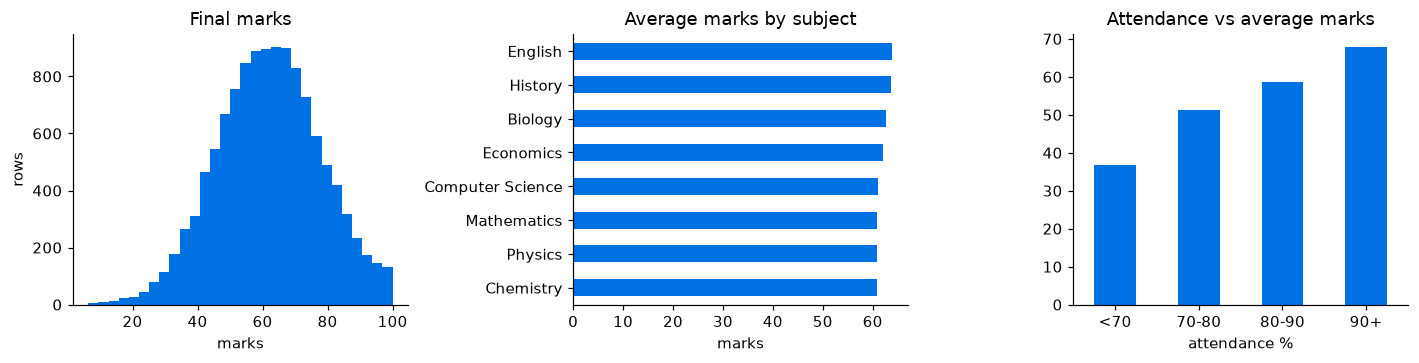

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
df.final_marks.plot.hist(bins=30, ax=ax[0], color=BLUE)
ax[0].set(title="Final marks", xlabel="marks", ylabel="rows")
df.groupby("subject").final_marks.mean().sort_values().plot.barh(ax=ax[1], color=BLUE)
ax[1].set(title="Average marks by subject", xlabel="marks", ylabel="")
att = pd.cut(df.attendance_pct, [0, 70, 80, 90, 101], labels=["<70", "70-80", "80-90", "90+"])
df.groupby(att, observed=True).final_marks.mean().plot.bar(ax=ax[2], color=BLUE, rot=0)
ax[2].set(title="Attendance vs average marks", xlabel="attendance %", ylabel="")
plt.tight_layout()

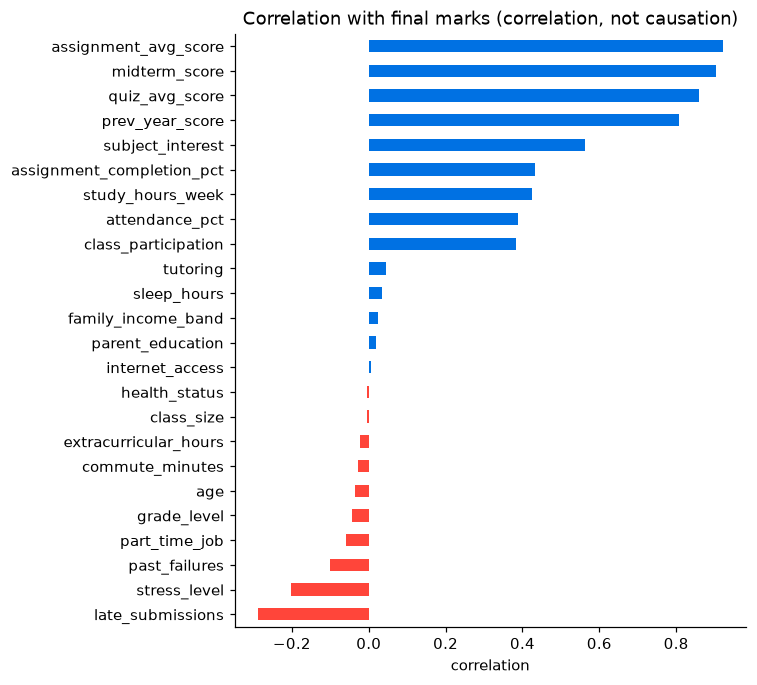

In [5]:
corr = df.select_dtypes("number").corr()["final_marks"].drop(["final_marks", "final_exam_score", "passed"]).sort_values()
corr.plot.barh(figsize=(6, 7), color=np.where(corr > 0, BLUE, "#ff453a"))
plt.title("Correlation with final marks (correlation, not causation)")
plt.xlabel("correlation");

## 3. Preprocessing and split
Three networks use the same architecture but different inputs, depending on **when the information is available**:

| Network | Inputs known at | Adds |
|---|---|---|
| `early` | start of the term | home, lifestyle, subject, last year's score |
| `during_term` | during the term | + attendance, study hours, assignments, quizzes, participation |
| `late` | after the mid-term | + mid-term and assignment average (parts of the final mark) |

The columns that contain or come from the target (`final_exam_score`, `grade_letter`, `passed`) are never used as inputs.
Numbers are standardised (mean 0, standard deviation 1) and categories become 0/1 columns. The means and standard deviations
come from the **training** rows only, so nothing about the test students leaks into training.

In [6]:
# ---- which columns each network uses ----
TARGET = "final_marks"


EARLY_NUMERIC = ["age", "grade_level", "parent_education", "family_income_band", "commute_minutes",
                 "extracurricular_hours", "sleep_hours", "stress_level", "health_status", "past_failures",
                 "subject_interest", "class_size", "prev_year_score"]


TERM_NUMERIC = ["study_hours_week", "attendance_pct", "assignment_completion_pct", "late_submissions",
                "class_participation", "quiz_avg_score"]


LATE_NUMERIC = ["midterm_score", "assignment_avg_score"]


BINARY = ["gender", "internet_access", "part_time_job", "tutoring"]


CATEGORICAL = ["subject"]


VARIANT_NUMERIC = {
    "early": EARLY_NUMERIC,
    "during_term": EARLY_NUMERIC + TERM_NUMERIC,
    "late": EARLY_NUMERIC + TERM_NUMERIC + LATE_NUMERIC,
}


EXCLUDED = ["final_exam_score", "grade_letter", "passed", TARGET]

In [7]:
# ---- split by student, fit the scaling on the training rows, transform ----
def group_split(df, seed=42, val=0.15, test=0.15):
    """70/15/15 split in which every student (all 6 of their rows) stays in one split."""
    groups = df["student_id"]
    outer = GroupShuffleSplit(n_splits=1, test_size=test, random_state=seed)
    trainval, test_idx = next(outer.split(df, groups=groups))
    inner = GroupShuffleSplit(n_splits=1, test_size=val / (1 - test), random_state=seed)
    tr, va = next(inner.split(df.iloc[trainval], groups=groups.iloc[trainval]))
    return trainval[tr], trainval[va], test_idx


def fit_config(train_df, variant="late"):
    """Learn scaling / category lists from the training split only."""
    features = []
    for col in VARIANT_NUMERIC[variant]:
        s = train_df[col]
        features.append({"name": col, "kind": "numeric", "mean": float(s.mean()),
                         "std": float(s.std(ddof=0)) or 1.0, "min": float(s.min()),
                         "max": float(s.max()), "default": float(s.median()),
                         "integer": bool((s == s.round()).all())})
    for col in BINARY:
        opts = sorted(train_df[col].unique().tolist())
        features.append({"name": col, "kind": "binary", "options": opts,
                         "default": train_df[col].mode().tolist()[0]})
    for col in CATEGORICAL:
        opts = sorted(train_df[col].unique().tolist())
        features.append({"name": col, "kind": "categorical", "options": opts,
                         "default": train_df[col].mode().tolist()[0]})
    return {"features": features, "target_mean": float(train_df[TARGET].mean()),
            "target_std": float(train_df[TARGET].std(ddof=0)), "variant": variant}


def column_names(cfg):
    """Names of the network input columns, in order."""
    names = []
    for f in cfg["features"]:
        if f["kind"] == "categorical":
            names += [f"{f['name']}={o}" for o in f["options"]]
        else:
            names.append(f["name"])
    return names


def transform(df, cfg):
    """Raw rows -> scaled float matrix (n, n_inputs). Rejects unseen categories."""
    cols = []
    for f in cfg["features"]:
        v = df[f["name"]]
        if f["kind"] == "numeric":
            cols.append(((v - f["mean"]) / f["std"]).to_numpy(float))
            continue
        if not v.isin(f["options"]).all():
            raise ValueError(f"{f['name']}: value not in {f['options']}")
        if f["kind"] == "binary":
            cols.append((v == f["options"][1]).to_numpy(float))
        else:
            cols += [(v == o).to_numpy(float) for o in f["options"]]
    return np.column_stack(cols)


def scale_target(marks, cfg):
    return (np.asarray(marks, float) - cfg["target_mean"]) / cfg["target_std"]


def unscale_target(z, cfg):
    return np.asarray(z, float) * cfg["target_std"] + cfg["target_mean"]

Split: train 70% / validation 15% / test 15%, **by student**, so the same student never appears in two parts. The test part is used once, at the end.

In [8]:
tr, va, te = group_split(df, seed=42)
parts = {name: df.iloc[idx] for name, idx in zip(("train", "val", "test"), (tr, va, te))}
students = {name: set(d.student_id) for name, d in parts.items()}
for name, d in parts.items():
    print(f"{name:5s}: {len(d):>5,} rows, {len(students[name]):>4} students")
assert not (students["train"] & students["val"] or students["train"] & students["test"] or students["val"] & students["test"])
print("No student appears in more than one part.")

train: 8,400 rows, 1400 students
val  : 1,800 rows,  300 students
test : 1,800 rows,  300 students
No student appears in more than one part.


## 4. The neural network
```
 inputs (25 / 31 / 33)        hidden layer (16 neurons)           output (1 neuron)

 x1 ─┐
 x2 ─┤   z1 = X·W1 + b1                                            ŷ = a1·W2 + b2
 x3 ─┼──────────────►  a1 = ReLU(z1) = max(0, z1)  ───────────►   predicted marks
 ⋮   │   (weights W1, biases b1)                                   (weights W2, bias b2, linear)
 xn ─┘
```
**Forward pass:** `z1 = X·W1 + b1`, `a1 = max(0, z1)`, `ŷ = a1·W2 + b2`. **Loss:** `MSE = mean((ŷ − y)²)`.

**Backpropagation** (chain rule, `n` = rows in the mini-batch):
`dz2 = 2(ŷ − y)/n`, `dW2 = a1ᵀ·dz2`, `db2 = Σ dz2`, `dz1 = (dz2·W2ᵀ) ⊙ [z1 > 0]`, `dW1 = Xᵀ·dz1`, `db1 = Σ dz1`.

**Gradient descent:** every weight moves a small step against its gradient, `w ← w − η · dw`, on mini-batches of rows, and training
stops early when the validation loss stops improving (the best weights are restored).

In [9]:
# ---- the network: forward pass, backpropagation, gradient descent ----
class MLP:
    def __init__(self, n_inputs, n_hidden=16, seed=0):
        rng = np.random.default_rng(seed)
        self.params = {  # He initialisation suits ReLU layers
            "W1": rng.normal(0, np.sqrt(2 / n_inputs), (n_inputs, n_hidden)),
            "b1": np.zeros((1, n_hidden)),
            "W2": rng.normal(0, np.sqrt(1 / n_hidden), (n_hidden, 1)),
            "b2": np.zeros((1, 1)),
        }

    # ---- forward propagation ------------------------------------------------
    def forward(self, X, params=None):
        p = params or self.params
        z1 = X @ p["W1"] + p["b1"]          # weighted sum of hidden neurons
        a1 = np.maximum(0.0, z1)            # ReLU activation
        y_hat = a1 @ p["W2"] + p["b2"]      # linear output neuron
        return y_hat, (X, z1, a1)

    def predict(self, X):
        return self.forward(X)[0].ravel()

    @staticmethod
    def mse(y_hat, y):
        return float(np.mean((y_hat - y) ** 2))

    # ---- backpropagation (chain rule, layer by layer) ------------------------
    def backward(self, cache, y_hat, y):
        X, z1, a1 = cache
        n = len(y)
        dz2 = 2.0 * (y_hat - y) / n                 # dL/dz2
        dW2 = a1.T @ dz2
        db2 = dz2.sum(axis=0, keepdims=True)
        dz1 = (dz2 @ self.params["W2"].T) * (z1 > 0)  # ReLU derivative
        dW1 = X.T @ dz1
        db1 = dz1.sum(axis=0, keepdims=True)
        return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

    # ---- gradient descent ---------------------------------------------------
    def fit(self, X, y, X_val, y_val, lr=0.01, epochs=800, batch_size=32,
            patience=80, seed=0):
        """Mini-batch gradient descent with early stopping on validation MSE.

        Restores the weights from the best validation epoch. Returns the history.
        """
        y, y_val = y.reshape(-1, 1), y_val.reshape(-1, 1)
        rng = np.random.default_rng(seed)
        history, best, best_params, since_best = [], np.inf, None, 0
        for epoch in range(1, epochs + 1):
            order = rng.permutation(len(X))
            for start in range(0, len(X), batch_size):
                idx = order[start:start + batch_size]
                y_hat, cache = self.forward(X[idx])
                grads = self.backward(cache, y_hat, y[idx])
                for k in self.params:                      # weight update
                    self.params[k] -= lr * grads[k]
            train_loss = self.mse(self.forward(X)[0], y)
            val_loss = self.mse(self.forward(X_val)[0], y_val)
            history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})
            if val_loss < best - 1e-6:
                best, best_params, since_best = val_loss, copy.deepcopy(self.params), 0
            else:
                since_best += 1
                if since_best >= patience:
                    break
        self.params = best_params
        return history

    # ---- persistence --------------------------------------------------------
    def save(self, path):
        np.savez(path, **self.params)

    @classmethod
    def load(cls, path):
        data = np.load(path)
        net = cls(data["W1"].shape[0], data["W1"].shape[1])
        net.params = {k: data[k] for k in ("W1", "b1", "W2", "b2")}
        return net

A numerical check of the gradients (used in section 7), and the evaluation metrics:

In [10]:
# ---- numerical gradient check ----
def gradient_check(net, X, y, eps=1e-5):
    """Max relative error between backprop gradients and central differences."""
    y = y.reshape(-1, 1)
    # ReLU is not differentiable at 0: drop samples whose pre-activations sit
    # within the finite-difference step of the kink.
    keep = np.abs(net.forward(X)[1][1]).min(axis=1) > 1e-3
    X, y = X[keep], y[keep]
    y_hat, cache = net.forward(X)
    analytic = net.backward(cache, y_hat, y)
    worst = 0.0
    for name, w in net.params.items():
        for i in np.ndindex(w.shape):
            orig = w[i]
            w[i] = orig + eps
            plus = net.mse(net.forward(X)[0], y)
            w[i] = orig - eps
            minus = net.mse(net.forward(X)[0], y)
            w[i] = orig
            numeric = (plus - minus) / (2 * eps)
            denom = max(abs(numeric) + abs(analytic[name][i]), 1e-12)
            worst = max(worst, abs(numeric - analytic[name][i]) / denom)
    return worst

In [11]:
# ---- evaluation metrics (marks are on a 0-100 scale) ----
def mae(y, y_hat):
    return float(np.mean(np.abs(np.asarray(y) - np.asarray(y_hat))))


def rmse(y, y_hat):
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(y_hat)) ** 2)))


def r2(y, y_hat):
    y, y_hat = np.asarray(y), np.asarray(y_hat)
    ss_tot = np.sum((y - y.mean()) ** 2)
    return float(1 - np.sum((y - y_hat) ** 2) / ss_tot)


def summarize(y, y_hat):
    return {"mae": mae(y, y_hat), "rmse": rmse(y, y_hat), "r2": r2(y, y_hat)}

## 5. Training
The three networks are trained here (a few seconds each). The untrained starting network is kept so that we can compare before and after.

In [12]:
FIT = dict(lr=0.01, epochs=300, batch_size=128, patience=25, seed=42)   # learning rate, max epochs, mini-batch size, early-stopping patience

trained = {}
for v in VARIANTS:
    cfg = fit_config(parts["train"], variant=v)
    X = {k: transform(d, cfg) for k, d in parts.items()}
    y = {k: scale_target(d[TARGET], cfg) for k, d in parts.items()}
    net = MLP(X["train"].shape[1], 16, seed=42)
    start = copy.deepcopy(net)                                  # weights before any learning
    history = pd.DataFrame(net.fit(X["train"], y["train"], X["val"], y["val"], **FIT))
    trained[v] = dict(net=net, start=start, cfg=cfg, X=X, y=y, history=history)
    print(f"{v:12s}: {X['train'].shape[1]} inputs, stopped after {len(history)} epochs, "
          f"best validation loss {history.val_loss.min():.3f}")

early       : 25 inputs, stopped after 200 epochs, best validation loss 0.273


during_term : 31 inputs, stopped after 220 epochs, best validation loss 0.152


late        : 33 inputs, stopped after 300 epochs, best validation loss 0.057


## 6. One prediction by hand
Follow one test row through the trained `during_term` network, step by step.

In [13]:
net, cfg = trained["during_term"]["net"], trained["during_term"]["cfg"]
row = parts["test"].iloc[[0]]
x = transform(row, cfg)                       # scaled with TRAIN statistics only
y_hat, (_, z1, a1) = net.forward(x)           # z1 = x.W1 + b1 ; a1 = ReLU(z1) ; y_hat = a1.W2 + b2

print(row[["student_id", "subject", "prev_year_score", "attendance_pct", "study_hours_week", "quiz_avg_score"]].to_string(index=False))
hidden = pd.DataFrame({"z1 (before ReLU)": z1.ravel(), "a1 = max(0, z1)": a1.ravel(),
                       "W2": net.params["W2"].ravel(), "a1 x W2": a1.ravel() * net.params["W2"].ravel()}).round(3)
hidden.index.name = "hidden neuron"
hidden

student_id     subject  prev_year_score  attendance_pct  study_hours_week  quiz_avg_score
     S0023 Mathematics             62.1            85.6               2.3            66.8


,z1 (before ReLU),"a1 = max(0, z1)",W2,a1 x W2
hidden neuron,,,,
0,-0.183,0.000,-0.349,-0.000
1,-0.107,0.000,0.144,0.000
2,0.138,0.138,-0.105,-0.014
3,1.325,1.325,-0.085,-0.113
4,0.126,0.126,0.296,0.037
5,0.251,0.251,-0.090,-0.023
6,-0.882,0.000,-0.010,-0.000
7,0.931,0.931,-0.040,-0.037
8,-0.805,0.000,-0.057,-0.000


In [14]:
total = float((a1 @ net.params["W2"])[0, 0])
b2 = float(net.params["b2"][0, 0])
print(f"sum(a1 x W2) = {total:.3f}   bias b2 = {b2:.3f}   ->  standardised output = {float(y_hat[0, 0]):.3f}")
pred = float(unscale_target(y_hat, cfg)[0, 0])
print(f"x {cfg['target_std']:.2f} + {cfg['target_mean']:.2f}  ->  predicted {pred:.1f} marks   (actual: {row.final_marks.iloc[0]:.1f})")

sum(a1 x W2) = -0.350   bias b2 = 0.014   ->  standardised output = -0.337
x 15.66 + 61.92  ->  predicted 56.6 marks   (actual: 54.2)


## 7. Is backpropagation correct?
Compare the gradients computed by backpropagation with numerical (finite-difference) gradients.

In [15]:
t = trained["early"]
small = parts["train"].head(20)
err = gradient_check(t["net"], transform(small, t["cfg"]), scale_target(small[TARGET], t["cfg"]))
print(f"max relative error between backpropagation and numerical gradients: {err:.2e}")
assert err < 1e-5

max relative error between backpropagation and numerical gradients: 1.49e-07


## 8. Learning curves and weight changes
Training and validation loss per epoch, and how the 16 output weights `W2` moved from their random start.

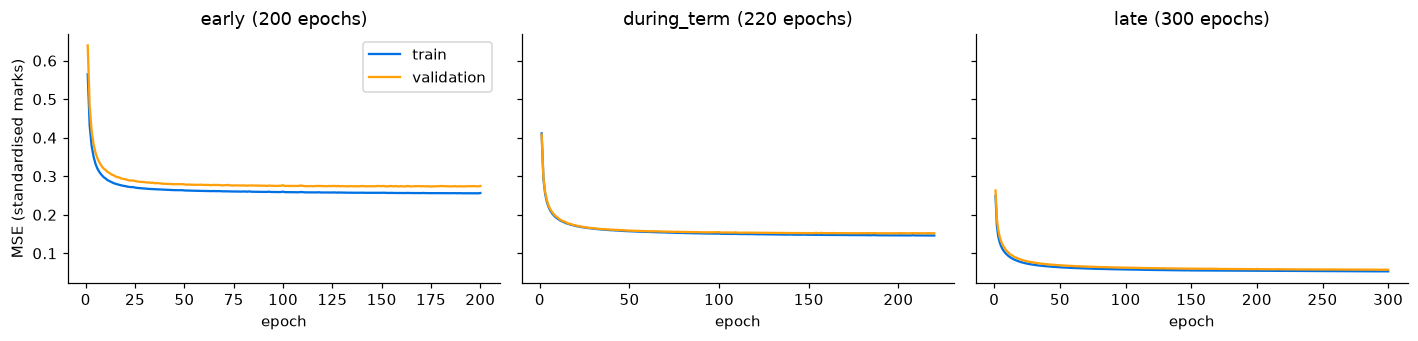

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for a, v in zip(ax, VARIANTS):
    h = trained[v]["history"]
    a.plot(h.epoch, h.train_loss, label="train", color=BLUE)
    a.plot(h.epoch, h.val_loss, label="validation", color=ORANGE)
    a.set(title=f"{v} ({len(h)} epochs)", xlabel="epoch")
ax[0].set_ylabel("MSE (standardised marks)")
ax[0].legend()
plt.tight_layout()

,actual,predicted before training,predicted after training
student_id,,,
S0023 / Mathematics,54.2,32.9,56.6
S0023 / English,54.2,40.2,55.8
S0023 / History,69.7,40.6,60.9
S0023 / Biology,55.4,36.7,63.5
S0023 / Economics,60.3,29.7,62.9


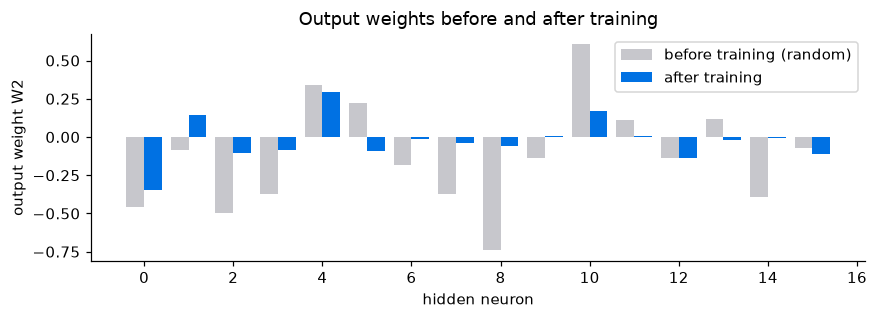

In [17]:
t = trained["during_term"]
fig, ax = plt.subplots(figsize=(8, 3))
idx = np.arange(16)
ax.bar(idx - .2, t["start"].params["W2"].ravel(), width=.4, label="before training (random)", color="#c7c7cc")
ax.bar(idx + .2, t["net"].params["W2"].ravel(), width=.4, label="after training", color=BLUE)
ax.set(xlabel="hidden neuron", ylabel="output weight W2", title="Output weights before and after training")
ax.legend()
plt.tight_layout()

probe = parts["test"].head(5)
before = unscale_target(t["start"].predict(transform(probe, t["cfg"])), t["cfg"])
after = unscale_target(t["net"].predict(transform(probe, t["cfg"])), t["cfg"])
pd.DataFrame({"actual": probe.final_marks.to_numpy(), "predicted before training": before, "predicted after training": after},
             index=probe.student_id.str.cat(probe.subject, sep=" / ")).round(1)

## 9. Test results
The 1,800 test rows (300 students the networks have never seen), used once. The baseline always predicts the average training mark.

In [18]:
test = parts["test"]
preds = test[["student_id", "subject", TARGET]].rename(columns={TARGET: "actual"}).reset_index(drop=True)
result_rows = [{"model": "baseline: predict the training mean",
                **summarize(test[TARGET], np.full(len(test), parts["train"][TARGET].mean()))}]
for v in VARIANTS:
    t = trained[v]
    preds[f"pred_{v}"] = unscale_target(t["net"].predict(t["X"]["test"]), t["cfg"])
    result_rows.append({"model": v, **summarize(preds.actual, preds[f"pred_{v}"])})
pd.DataFrame(result_rows).set_index("model").round(2)

,mae,rmse,r2
model,,,
baseline: predict the training mean,13.13,16.52,-0.00
early,6.64,8.36,0.74
during_term,4.99,6.26,0.86
late,3.01,3.77,0.95


Actual and predicted marks for the first test rows:

In [19]:
preds.head(10).round(1)

,student_id,subject,actual,pred_early,pred_during_term,pred_late
0,S0023,Mathematics,54.2,59.3,56.6,54.4
1,S0023,English,54.2,61.0,55.8,47.7
2,S0023,History,69.7,62.3,60.9,65.2
3,S0023,Biology,55.4,58.7,63.5,60.0
4,S0023,Economics,60.3,62.1,62.9,60.2
5,S0023,Computer Science,51.8,61.3,57.7,57.7
6,S0029,Mathematics,60.8,46.3,50.2,53.3
7,S0029,English,52.9,53.9,57.2,61.8
8,S0029,History,49.5,49.1,40.9,51.6
9,S0029,Physics,73.3,68.8,68.3,74.9


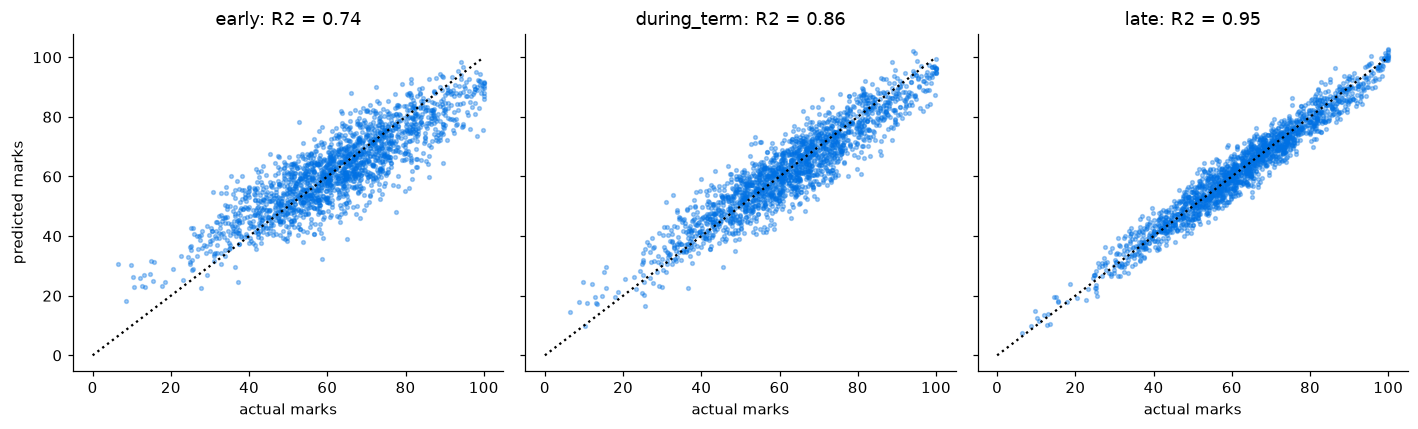

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
for a, v in zip(ax, VARIANTS):
    a.scatter(preds.actual, preds[f"pred_{v}"], s=6, alpha=.35, color=BLUE)
    a.plot([0, 100], [0, 100], "k:")
    a.set(title=f"{v}: R2 = {summarize(preds.actual, preds[f'pred_{v}'])['r2']:.2f}", xlabel="actual marks")
ax[0].set_ylabel("predicted marks")
plt.tight_layout()

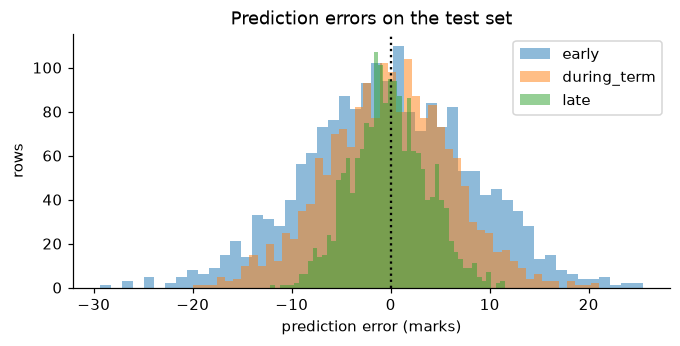

In [21]:
fig, ax = plt.subplots(figsize=(7, 3))
for v in VARIANTS:
    ax.hist(preds[f"pred_{v}"] - preds.actual, bins=50, alpha=.5, label=v)
ax.axvline(0, color="k", ls=":")
ax.set(xlabel="prediction error (marks)", ylabel="rows", title="Prediction errors on the test set")
ax.legend();

## 10. One student, all subjects
The network predicts one **student-subject** row at a time. Averaging a student's rows gives an overall estimate.

In [22]:
sid = preds.groupby("student_id").size().loc[lambda s: s == 6].index[0]
one = preds[preds.student_id == sid].set_index("subject")[["actual", "pred_early", "pred_during_term", "pred_late"]]
one.loc["AVERAGE"] = one.mean()
print("Student:", sid)
one.round(1)

Student: S0023


,actual,pred_early,pred_during_term,pred_late
subject,,,,
Mathematics,54.2,59.3,56.6,54.4
English,54.2,61.0,55.8,47.7
History,69.7,62.3,60.9,65.2
Biology,55.4,58.7,63.5,60.0
Economics,60.3,62.1,62.9,60.2
Computer Science,51.8,61.3,57.7,57.7
AVERAGE,57.6,60.8,59.6,57.5


In [23]:
by_student = preds.groupby("student_id")[["actual", "pred_early", "pred_during_term", "pred_late"]].mean()
print(f"Across {len(by_student)} unseen test students, error of the student's average marks:")
pd.DataFrame({v: summarize(by_student.actual, by_student[f"pred_{v}"]) for v in VARIANTS}).T.round(2)

Across 300 unseen test students, error of the student's average marks:


,mae,rmse,r2
early,4.21,5.16,0.88
during_term,2.25,2.78,0.96
late,1.30,1.56,0.99


## 11. Classic neuron models
Three small models from the syllabus, with every calculation shown. They use tiny logic examples (AND / OR), not the student data.
The cell below defines them; the cells after it run them.

**McCulloch-Pitts neuron**: binary inputs, fixed weights, fires (outputs 1) when the weighted sum reaches a threshold.
**Hebb's rule**: weights grow when input and output are active together: `Δw = x · y`, `Δb = y` (bipolar AND, one pass).
**Delta rule**: a single linear neuron reduces its error step by step: `w ← w + η · (target − output) · x` (learning AND, η = 0.1).

In [24]:
# ---- McCulloch-Pitts, Hebb, Delta rule on logic examples ----
def mp_neuron(x, w, threshold):
    net = int(np.dot(x, w))
    return net, int(net >= threshold)


def demo_mp(gate="AND"):
    """AND needs threshold 2, OR needs threshold 1 (weights are both +1)."""
    threshold = {"AND": 2, "OR": 1}[gate]
    w = [1, 1]
    rows = []
    for x in [(0, 0), (0, 1), (1, 0), (1, 1)]:
        net, out = mp_neuron(x, w, threshold)
        rows.append({"x1": x[0], "x2": x[1], "w1": w[0], "w2": w[1],
                     "weighted_sum": net, "threshold": threshold, "output": out})
    return rows


def demo_hebb():
    """Learn bipolar AND with one pass of Hebb's rule. Returns (rows, weights, bias)."""
    X = [(1, 1), (1, -1), (-1, 1), (-1, -1)]
    T = [1, -1, -1, -1]
    w, b, rows = np.zeros(2), 0, []
    for x, t in zip(X, T):
        dw = np.array(x) * t
        w, b = w + dw, b + t
        rows.append({"x1": x[0], "x2": x[1], "target": t, "dw1": int(dw[0]),
                     "dw2": int(dw[1]), "db": t, "w1": int(w[0]), "w2": int(w[1]), "b": int(b)})
    return rows, w, b


def demo_delta(lr=0.1, epochs=30):
    """Train a single linear neuron on AND (0/1). Returns (step rows, epoch MSEs, w, b)."""
    X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], float)
    T = np.array([0, 0, 0, 1], float)
    w, b, rows, losses = np.zeros(2), 0.0, [], []
    for epoch in range(1, epochs + 1):
        sq = 0.0
        for x, t in zip(X, T):
            y = float(w @ x + b)
            err = t - y
            w, b = w + lr * err * x, b + lr * err
            sq += err ** 2
            rows.append({"epoch": epoch, "x1": x[0], "x2": x[1], "target": t,
                         "output": round(y, 4), "error": round(err, 4),
                         "w1": round(w[0], 4), "w2": round(w[1], 4), "b": round(b, 4)})
        losses.append(sq / len(X))
    return rows, losses, w, b

In [25]:
pd.concat({gate: pd.DataFrame(demo_mp(gate)) for gate in ("AND", "OR")}, names=["gate"]).droplevel(1)

,x1,x2,w1,w2,weighted_sum,threshold,output
gate,,,,,,,
AND,0,0,1,1,0,2,0
AND,0,1,1,1,1,2,0
AND,1,0,1,1,1,2,0
AND,1,1,1,1,2,2,1
OR,0,0,1,1,0,1,0
OR,0,1,1,1,1,1,1
OR,1,0,1,1,1,1,1
OR,1,1,1,1,2,1,1


In [26]:
hebb_rows, hebb_w, hebb_b = demo_hebb()
print("Hebb's rule - final weights:", hebb_w.astype(int).tolist(), "| bias:", int(hebb_b))
pd.DataFrame(hebb_rows)

Hebb's rule - final weights: [2, 2] | bias: -2


,x1,x2,target,dw1,dw2,db,w1,w2,b
0,1,1,1,1,1,1,1,1,1
1,1,-1,-1,-1,1,-1,0,2,0
2,-1,1,-1,1,-1,-1,1,1,-1
3,-1,-1,-1,1,1,-1,2,2,-2


Delta rule - final weights [0.505, 0.476], bias -0.209 | mean squared error 0.250 -> 0.079


,epoch,x1,x2,target,output,error,w1,w2,b
0,1,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0000,0.0000
1,1,0.0,1.0,0.0,0.0000,0.0000,0.0000,0.0000,0.0000
2,1,1.0,0.0,0.0,0.0000,0.0000,0.0000,0.0000,0.0000
3,1,1.0,1.0,1.0,0.0000,1.0000,0.1000,0.1000,0.1000
4,2,0.0,0.0,0.0,0.1000,-0.1000,0.1000,0.1000,0.0900
5,2,0.0,1.0,0.0,0.1900,-0.1900,0.1000,0.0810,0.0710
6,2,1.0,0.0,0.0,0.1710,-0.1710,0.0829,0.0810,0.0539
7,2,1.0,1.0,1.0,0.2178,0.7822,0.1611,0.1592,0.1321


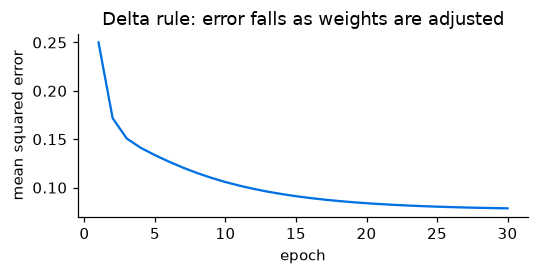

In [27]:
steps, losses, toy_w, toy_b = demo_delta(lr=0.1, epochs=30)
print(f"Delta rule - final weights {np.round(toy_w, 3).tolist()}, bias {toy_b:.3f} | mean squared error {losses[0]:.3f} -> {losses[-1]:.3f}")
fig, ax = plt.subplots(figsize=(5, 2.6))
ax.plot(range(1, len(losses) + 1), losses, color=BLUE)
ax.set(xlabel="epoch", ylabel="mean squared error", title="Delta rule: error falls as weights are adjusted")
plt.tight_layout()
pd.DataFrame(steps).head(8)

## 12. Delta rule on the student data
The Delta rule, applied to the student data: one linear neuron learns to predict final marks from **attendance, quiz average and study hours**,
one student at a time. We compare it with the best straight-line fit (the most a single neuron can do) and with the 16-neuron network.
Backpropagation extends the same error-driven idea through hidden layers using the chain rule; it is not identical to the single-neuron Delta rule.

In [28]:
# ---- Delta rule on a dataset, and the closed-form best straight line ----
def delta_rule_fit(X, y, X_val, y_val, lr=0.01, epochs=10, seed=0, n_steps=5):
    """Train y_hat = w.x + b with the Delta rule, one sample at a time (shuffled each epoch).

    Returns a dict with: `checkpoints` (validation MSE and weights after 0, 1, 2, 5, 10 ... updates and after every
    epoch - the neuron learns most within the first epoch, so a per-epoch view alone looks flat), the per-epoch
    `weights`/`biases`/`val_mse`, the first `n_steps` updates (x, output, error, weights after) and a `diverged` flag.
    """
    rng = np.random.default_rng(seed)
    w, b = np.zeros(X.shape[1]), 0.0
    marks = {0, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000}
    weights, biases, val_mse, steps, checkpoints = [], [], [], [], []

    def checkpoint(n):
        checkpoints.append({"updates": n, "val_mse": float(np.mean((X_val @ w + b - y_val) ** 2)), "w": w.copy()})

    def result(diverged):
        return {"weights": weights, "biases": biases, "val_mse": val_mse, "steps": steps,
                "checkpoints": checkpoints, "diverged": diverged}

    n = 0
    with np.errstate(over="ignore", invalid="ignore"):  # diverging runs are reported via `diverged`
        checkpoint(0)
        for epoch in range(epochs):
            for i in rng.permutation(len(X)):
                out = float(w @ X[i] + b)
                err = float(y[i] - out)
                w, b = w + lr * err * X[i], b + lr * err
                n += 1
                if epoch == 0 and len(steps) < n_steps:
                    steps.append({"x": X[i].copy(), "output": out, "target": float(y[i]), "error": err,
                                  "w": w.copy(), "b": b})
                if n in marks and n < epochs * len(X):
                    checkpoint(n)
            weights.append(w.copy())
            biases.append(b)
            checkpoint(n)
            val_mse.append(checkpoints[-1]["val_mse"])
            if not np.isfinite(w).all():
                return result(True)
    return result(False)


def least_squares(X, y):
    """Closed-form best linear neuron (weights, bias) - the target the Delta rule converges toward."""
    coef = np.linalg.lstsq(np.column_stack([X, np.ones(len(X))]), y, rcond=None)[0]
    return coef[:-1], float(coef[-1])

In [29]:
cfg_dt = trained["during_term"]["cfg"]
stats = {f["name"]: f for f in cfg_dt["features"]}
FEATURES = ["attendance_pct", "quiz_avg_score", "study_hours_week"]
design = lambda d: np.column_stack([(d[n] - stats[n]["mean"]) / stats[n]["std"] for n in FEATURES])
Xd = {k: design(d) for k, d in parts.items()}
yd = {k: scale_target(d[TARGET], cfg_dt) for k, d in parts.items()}
std = cfg_dt["target_std"]

fit = delta_rule_fit(Xd["train"], yd["train"], Xd["val"], yd["val"], lr=0.01, epochs=10)
ls_w, ls_b = least_squares(Xd["train"], yd["train"])
rmse_marks = lambda w, b, k: float(np.sqrt(np.mean((Xd[k] @ w + b - yd[k]) ** 2)) * std)

w_end, b_end = fit["weights"][-1], fit["biases"][-1]
pd.DataFrame({"Delta-rule neuron": rmse_marks(w_end, b_end, "test"), "best straight line": rmse_marks(ls_w, ls_b, "test"),
              "16-neuron network (during_term)": summarize(preds.actual, preds.pred_during_term)["rmse"],
              "predict the mean": result_rows[0]["rmse"]}, index=["test RMSE (marks)"]).round(2)

,Delta-rule neuron,best straight line,16-neuron network (during_term),predict the mean
test RMSE (marks),8.05,7.78,6.26,16.52


,learned by Delta rule,best straight line
input,,
attendance_pct,2.51,2.17
quiz_avg_score,11.65,12.49
study_hours_week,-0.18,0.78


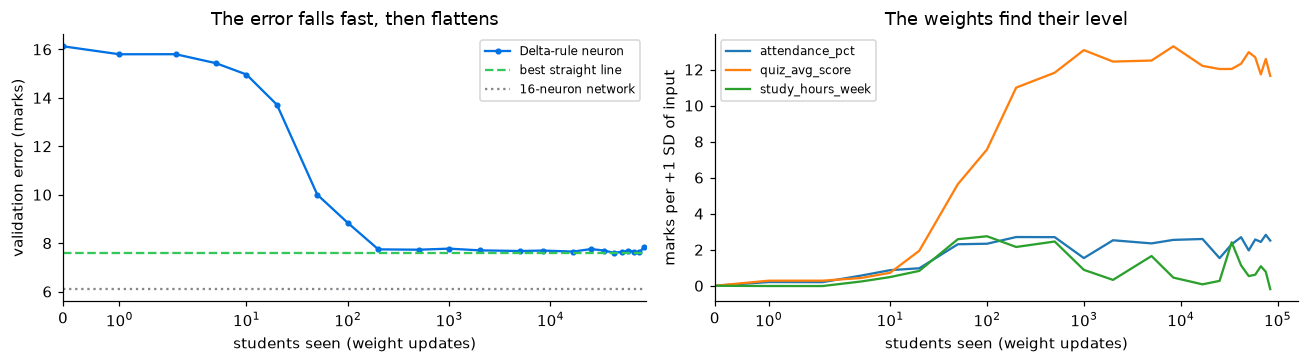

In [30]:
updates = [c["updates"] for c in fit["checkpoints"]]
val_rmse = [float(np.sqrt(c["val_mse"]) * std) for c in fit["checkpoints"]]
net_val = summarize(parts["val"][TARGET],
                    unscale_target(trained["during_term"]["net"].predict(trained["during_term"]["X"]["val"]), cfg_dt))["rmse"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].plot(updates, val_rmse, marker="o", ms=3, color=BLUE, label="Delta-rule neuron")
ax[0].axhline(rmse_marks(ls_w, ls_b, "val"), color="#34c759", ls="--", label="best straight line")
ax[0].axhline(net_val, color="#86868b", ls=":", label="16-neuron network")
ax[0].set(xscale="symlog", xlim=(0, None), xlabel="students seen (weight updates)", ylabel="validation error (marks)",
          title="The error falls fast, then flattens")
ax[0].legend(fontsize=8)
weights = np.array([c["w"] for c in fit["checkpoints"]]) * std
for j, n in enumerate(FEATURES):
    ax[1].plot(updates, weights[:, j], label=n)
ax[1].set(xscale="symlog", xlim=(0, None), xlabel="students seen (weight updates)", ylabel="marks per +1 SD of input",
          title="The weights find their level")
ax[1].legend(fontsize=8)
plt.tight_layout()

pd.DataFrame({"input": FEATURES, "learned by Delta rule": w_end * std, "best straight line": ls_w * std}).set_index("input").round(2)

The first five weight updates, step by step (standardised values; `output = w·x + b`, `error = target − output`):

In [31]:
pd.DataFrame([{"update": i, "output": s["output"], "target": s["target"], "error": s["error"],
               **{f"w[{n}]": float(wj) for n, wj in zip(FEATURES, s["w"])}} for i, s in enumerate(fit["steps"], 1)]).round(3)

,update,output,target,error,w[attendance_pct],w[quiz_avg_score],w[study_hours_week]
0,1,0.000,1.302,1.302,0.013,0.018,-0.001
1,2,0.001,0.031,0.030,0.013,0.018,-0.001
2,3,0.003,-0.212,-0.215,0.015,0.018,0.001
3,4,0.048,1.436,1.388,0.037,0.027,0.015
4,5,-0.035,0.031,0.066,0.036,0.028,0.015


## 13. Is 16 hidden neurons needed?
Validation error (RMSE in marks) for different hidden-layer sizes; the test rows are not used here.

In [32]:
sweep = {}
for v in VARIANTS:
    t = trained[v]
    sweep[v] = {}
    for h in (2, 4, 8, 16, 32):
        m = MLP(t["X"]["train"].shape[1], h, seed=42)
        m.fit(t["X"]["train"], t["y"]["train"], t["X"]["val"], t["y"]["val"], **FIT)
        sweep[v][h] = summarize(parts["val"][TARGET], unscale_target(m.predict(t["X"]["val"]), t["cfg"]))["rmse"]
pd.DataFrame(sweep).T.rename_axis("hidden neurons", axis=1).round(2)

hidden neurons,2,4,8,16,32
early,8.11,8.14,8.14,8.19,8.20
during_term,6.07,6.09,6.09,6.10,6.18
late,3.65,3.66,3.70,3.75,3.76


## 14. Limitations and next steps

**Observations**
- Each network beats the "predict the average" baseline by a wide margin, and accuracy rises as more information becomes available
  (`early` < `during_term` < `late`).
- The network trained on `late` inputs is the most accurate, but it partly reads the answer: mid-term and assignment average make up 40% of the final mark.
- Hidden-layer size barely matters, and the single Delta-rule neuron comes close to the network: the data is close to linear.
- Averaging a student's subjects reduces the error, because errors in different subjects partly cancel.

**Limitations**
- The data is synthetic: the networks recover what the generator contains, which says nothing about real students.
- 16 hidden neurons is a starting choice, not shown to be necessary or best. One split and one random seed; no confidence intervals.
- Predictions are statistical estimates from patterns, not guarantees, and they do not show that changing one input would cause the marks to change.

**Next steps**
- Validate on real student records and check fairness across groups.
- Repeat the experiment over several seeds / cross-validation and compare with other models (linear regression, tree ensembles).
- Add regularisation (L2, dropout), tune depth and learning rate, and report prediction uncertainty.